# SISMIGRA — cadastro por situação e recorte ativo

O arquivo `sismigra_ativos.csv` contém várias situações cadastrais. Portanto, o nome do arquivo não é usado como filtro: o recorte ativo exige explicitamente `situacao == ATIVO` após padronização.

Não há município, data de referência nem identificador pessoal nesta extração. A análise é nacional e por UF. Não atribuímos os registros a municípios, não tratamos o cadastro como população residente comprovada e não somamos seus totais aos arquivos anuais.

A coluna `pais` é analisada como **país informado pela fonte**. Sem um dicionário que defina sua semântica, não é identificada automaticamente como nascimento ou nacionalidade.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Funciona com o kernel iniciado na raiz do projeto ou em notebooks/.
RAIZ = Path.cwd() if (Path.cwd() / "src/migracao.py").exists() else Path.cwd().parent
if not (RAIZ / "src/migracao.py").exists():
    raise FileNotFoundError("Execute a partir da raiz do projeto ou de notebooks/.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.migracao import ARQUIVOS_ANUAIS, processar_anuais, processar_ativos

## 1. Limpeza por lotes e preservação do cadastro

São tratados espaços, caixa, UF e grafias de país, com os valores originais de país e UF preservados. A classificação inclui grafias como `TEMPORáRIO`, harmonizadas para `TEMPORÁRIO`. Todas as situações e linhas são conservadas no Parquet tratado.

Sem identificador pessoal, combinações repetidas das dimensões não são removidas: linhas iguais podem corresponder a registros distintos. O arquivo é processado por lotes para limitar o uso de memória.

In [2]:
resultados_ativos = processar_ativos(RAIZ)
display(resultados_ativos["qualidade_sismigra_ativos"])
display(resultados_ativos["ausencias"])

Cadastro: 3,879,289 registros; situação ATIVO: 2,080,214


,arquivo,registros_brutos,registros_tratados,registros_situacao_ativo,uf_ausente_ou_invalida,pais_nao_informado,data_referencia_informada,combinacoes_dimensoes,linhas_excedentes_mesmas_dimensoes
0,sismigra_ativos.csv,3879289,3879289,2080214,30866,4888,False,137289,3742000


,coluna,nulos_originais
0,amparo,0
1,classificacao,0
2,descricao_amparo,0
3,pais,1781
4,sexo,29
5,situacao,0
6,tipologia_amparos,0
7,unidade_da_federacao,30866


## 2. Situação cadastral: universo completo e recorte ativo

A participação por situação usa todas as linhas do arquivo. As análises seguintes de país e UF usam somente o subconjunto ativo. Cancelados, excluídos, inativos e prazos vencidos permanecem disponíveis na tabela por situação para auditoria e filtros.

,situacao,registros,participacao_pct
0,ATIVO,2080214,53.623589
4,PRAZO VENCIDO,1230125,31.710063
1,CANCELADO,500062,12.890558
3,INATIVO,63671,1.641306
2,EXCLUÍDO,5217,0.134483


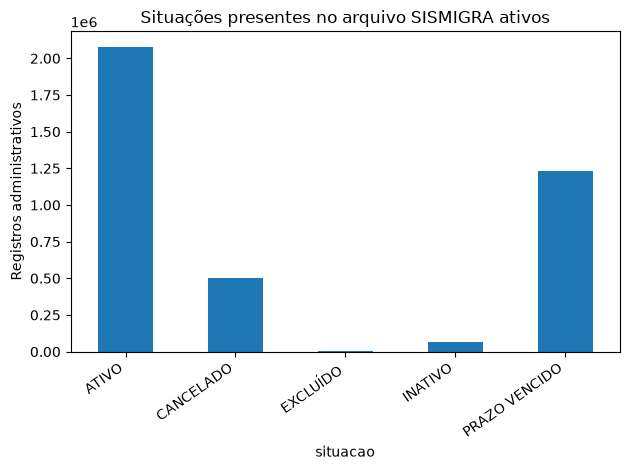

In [3]:
situacoes = resultados_ativos["situacoes_sismigra"].copy()
situacoes["participacao_pct"] = situacoes["registros"] / situacoes["registros"].sum() * 100
display(situacoes.sort_values("registros", ascending=False))
situacoes.plot.bar(x="situacao", y="registros", legend=False, title="Situações presentes no arquivo SISMIGRA ativos")
plt.ylabel("Registros administrativos")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 3. País informado pela fonte — apenas registros ativos

As participações incluem país não informado no denominador. Grafias como HOLANDA/PAÍSES BAIXOS e INDIA/ÍNDIA são harmonizadas; categorias históricas e territórios permanecem separados. A tabela de grafias permite auditar cada substituição.

,pais_id,pais_fonte,snapshot_id,criterio_pais,registros,participacao_pct
181,VENEZUELA,VENEZUELA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,643151,30.917540
23,BOLIVIA,BOLÍVIA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,176955,8.506577
137,PORTUGAL,PORTUGAL,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,149004,7.162917
78,HAITI,HAITI,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,129121,6.207102
9,ARGENTINA,ARGENTINA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,111183,5.344787
49,CUBA,CUBA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,91520,4.399547
41,COLOMBIA,COLÔMBIA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,71448,3.434647
38,CHINA,CHINA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,67470,3.243416
177,URUGUAI,URUGUAI,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,59510,2.860763
134,PARAGUAI,PARAGUAI,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,57212,2.750294


Participação dos cinco principais países: 58.14%


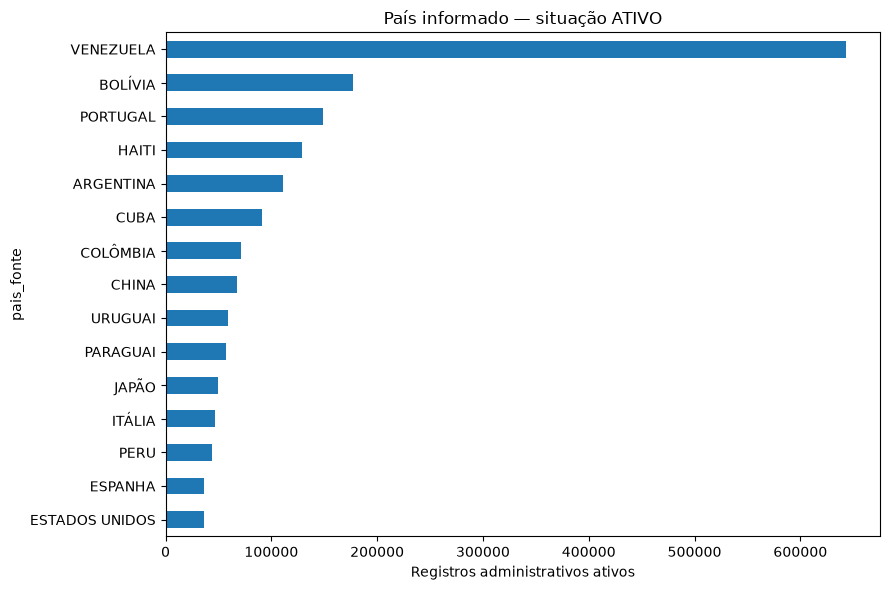

In [4]:
paises_ativos = resultados_ativos["fato_sismigra_ativos_pais"]
display(paises_ativos.nlargest(20, "registros"))
top5_pct = paises_ativos.nlargest(5, "registros")["participacao_pct"].sum()
print(f"Participação dos cinco principais países: {top5_pct:.2f}%")
paises_ativos.nlargest(15, "registros").sort_values("registros").plot.barh(
    x="pais_fonte", y="registros", legend=False, figsize=(9, 6), title="País informado — situação ATIVO"
)
plt.xlabel("Registros administrativos ativos")
plt.tight_layout()
plt.show()

In [5]:
grafias = resultados_ativos["grafias"].copy()
display(grafias[grafias["valor_original"].fillna("").ne(grafias["pais_padronizado"])])

,valor_original,pais_padronizado
0,<NA>,NÃO INFORMADO
28,HOLANDA,PAÍSES BAIXOS
49,BIELORRÚSSIA,BELARUS
53,CORÉIA DO SUL,COREIA DO SUL
67,CINGAPURA-SINGAPURA,CINGAPURA
71,NÃO ESPECIFICADO,NÃO INFORMADO
83,ESTADO DA PALESTINA,PALESTINA
96,AZERBAIDJÃO,AZERBAIJÃO
129,MOLDÁVIA,MOLDOVA
153,"MAURÍCIO, ILHAS",MAURÍCIO


## 4. Distribuição por UF, sexo, classificação e amparo

UF não informada/inválida recebe `NI` para que nenhum registro desapareça das somas. O país predominante por UF não informa a composição municipal nem a residência atual das pessoas.

In [6]:
uf_paises = resultados_ativos["fato_sismigra_ativos_uf_pais"]
por_uf = uf_paises.groupby("uf", as_index=False)["registros"].sum().sort_values("registros", ascending=False)
por_uf["participacao_nacional_pct"] = por_uf["registros"] / por_uf["registros"].sum() * 100
display(por_uf)
display(uf_paises.sort_values(["uf", "registros"], ascending=[True, False]).groupby("uf").head(3))

cadastro = resultados_ativos["fato_sismigra_situacao"]
recorte_ativo = cadastro[cadastro["situacao"].eq("ATIVO")]
for dimensao in ["sexo", "classificacao", "tipologia_amparos", "amparo"]:
    print(dimensao)
    display(recorte_ativo.groupby(dimensao, as_index=False)["registros"].sum().nlargest(15, "registros"))

,uf,registros,participacao_nacional_pct
26,SP,683487,32.856571
18,PR,222308,10.686785
24,SC,219076,10.531416
19,RJ,169713,8.158439
22,RR,164432,7.904571
23,RS,161502,7.763720
2,AM,82572,3.969399
10,MG,61703,2.966185
11,MS,40863,1.964365
12,MT,37925,1.823130


,uf,pais_id,pais_fonte,snapshot_id,criterio_pais,registros,participacao_pct
6,AC,BOLIVIA,BOLÍVIA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,2549,45.746590
42,AC,PERU,PERU,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,1253,22.487437
58,AC,VENEZUELA,VENEZUELA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,905,16.241924
64,AL,ARGENTINA,ARGENTINA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,635,14.064230
79,AL,COLOMBIA,COLÔMBIA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,597,13.222591
...,...,...,...,...,...,...,...
3213,SP,PORTUGAL,PORTUGAL,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,64953,9.503180
3255,SP,VENEZUELA,VENEZUELA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,50326,7.363125
3339,TO,VENEZUELA,VENEZUELA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,443,21.705047
3275,TO,COLOMBIA,COLÔMBIA,sismigra_ativos_sem_data_referencia,PAIS_DA_FONTE_SEM_DEFINICAO,253,12.395884


sexo


,sexo,registros
1,MASCULINO,1148488
0,FEMININO,931334
2,NÃO DECLARADO,368
3,NÃO INFORMADO,24


classificacao


,classificacao,registros
3,RESIDENTE,1495692
4,TEMPORÁRIO,452712
2,PROVISÓRIO,119326
1,FRONTEIRIÇO,12474
0,ASILADO,10


tipologia_amparos


,tipologia_amparos,registros
1,ACOLHIDA VENEZUELANOS,530120
7,OUTROS,448242
2,ACORDOS AMÉRICA DO SUL,378994
9,REUNIÃO FAMILIAR,328623
10,TRABALHO/INVESTIMENTOS,120799
6,NÃO APLICÁVEL,120237
8,REFÚGIO/ASILO,88997
0,ACOLHIDA HUMANITÁRIA,31197
3,ESTUDOS,15357
4,FRONTEIRIÇOS,12474


amparo


,amparo,registros
26,14,298227
144,299,266728
116,273,263392
130,286,230558
72,211,176928
135,290,119078
69,209,108226
131,287,88628
114,271,74217
62,200,57013


## 5. Reconciliação e preparação para o Power BI

O Parquet `sismigra_ativos_tratado` conserva todas as linhas e os campos originais de país e UF. `fato_sismigra_situacao` é a tabela agregada de todas as situações; `fato_sismigra_ativos_uf_pais` e `fato_sismigra_ativos_pais` são visões do subconjunto ativo.

Essas três tabelas representam o mesmo cadastro em níveis diferentes e não devem ter seus totais somados. `snapshot_id = sismigra_ativos_sem_data_referencia` identifica a extração disponível, sem inventar uma data de referência. Não há série histórica de ativos neste arquivo. O notebook 07 exporta as tabelas e dimensões para o Power BI.

### Conferir a consistência das tabelas de saída

A soma do cadastro por situação deve reproduzir o total bruto. As tabelas por país e por UF e país devem reproduzir o mesmo total filtrado pela situação ATIVO. Cada combinação de chaves deve aparecer uma única vez.

In [7]:
qualidade_ativos = resultados_ativos["qualidade_sismigra_ativos"].iloc[0]
total_ativo = int(situacoes.loc[situacoes["situacao"].eq("ATIVO"), "registros"].sum())
assert cadastro["registros"].sum() == qualidade_ativos["registros_brutos"]
assert paises_ativos["registros"].sum() == total_ativo
assert uf_paises["registros"].sum() == total_ativo
assert not uf_paises.duplicated(["uf", "pais_id", "snapshot_id"]).any()
assert not paises_ativos.duplicated(["pais_id", "snapshot_id"]).any()
print("Cadastro completo e recorte ativo reconciliados; nenhuma linha excluída na limpeza.")

Cadastro completo e recorte ativo reconciliados; nenhuma linha excluída na limpeza.
